Random Quadratic Bosonic Model Simulation
N=4, M=3, σ=0.8, ω0=1.0
Initial state: [2, 0, 0, 2]



C:\Users\DELL\bosonic-qiskit\src\bosonic_qiskit\operators.py:398: ComplexWarning: Casting complex values to real discards the imaginary part
  ns = ns.astype(int)


  Timestep 20/20  (t = 2.850)
Simulation finished.
Final total bosons: 4.0000 (should be 4)


C:\Users\DELL\AppData\Local\Temp\ipykernel_3384\772943503.py:203: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


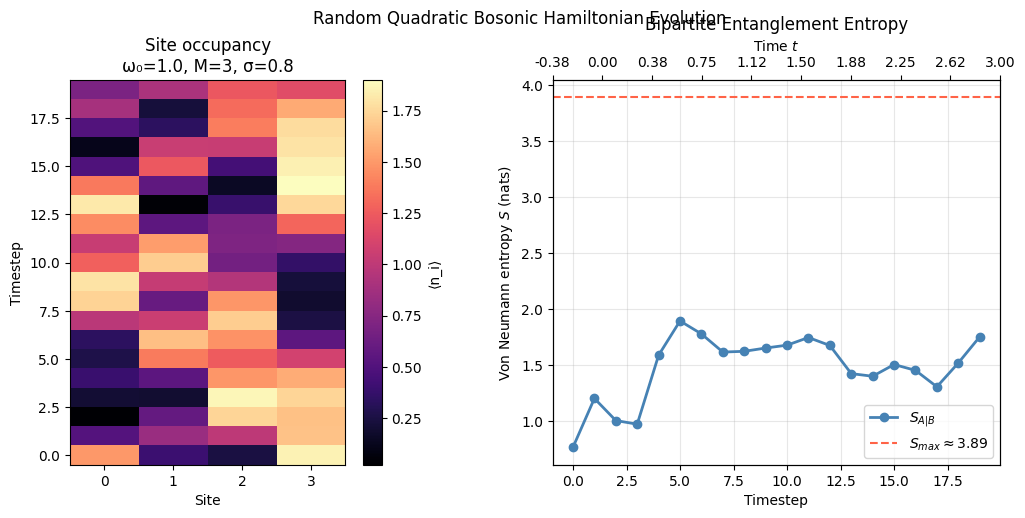

In [1]:
"""
Random Quadratic Bosonic Model Simulation
==========================================
Simulates N bosonic modes with the Hamiltonian:

H = ω₀ ∑ n̂_i + ∑_m |∑_i l_{m,i} b̂_i |²

Uses bosonic_qiskit (CV circuit framework).
Tracks site occupancies and bipartite von Neumann entanglement entropy.
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.linalg import svd, expm
import bosonic_qiskit
from qiskit.converters import circuit_to_gate


# ── Parameters & Random Couplings ─────────────────────────────────────────────

def generate_coupling_matrix(N, M, sigma, omega0, seed=42):
    """Generate the effective Hermitian matrix K."""
    np.random.seed(seed)
    # Complex Gaussian couplings l_{m,i}
    L = (np.random.randn(M, N) + 1j * np.random.randn(M, N)) * sigma / np.sqrt(2)
    interaction = L.conj().T @ L          # ∑_m l_m^* l_m  → rank-M update
    K = omega0 * np.eye(N) + interaction
    return K, L


# ── Trotter / Evolution Step ──────────────────────────────────────────────────

def build_trotter_step(Nsites, cutoff, K, dt):
    """
    Build one time-evolution gate ≈ exp(-i K dt) for the quadratic Hamiltonian.
    
    Since H = b† K b, the evolution is a Gaussian unitary.
    For small N we use a simple (but approximate for large dt) decomposition:
    - Apply beamsplitters according to the eigenvectors of K
    - Apply phase gates on normal modes
    - Inverse transformation
    """
    n_qubits_per_mode = int(np.ceil(np.log2(cutoff)))
    qmr = bosonic_qiskit.QumodeRegister(
        num_qumodes=Nsites,
        num_qubits_per_qumode=n_qubits_per_mode
    )
    circuit = bosonic_qiskit.CVCircuit(qmr)

    # Diagonalize K = U D U†
    eigenvalues, U = np.linalg.eigh(K)        # U is unitary

    # For small systems we can apply the linear optical unitary approximately
    # via successive beamsplitters (or use exact Gaussian gate if available).
    # Here we use a Trotter-like approach with pairwise beamsplitters.

    theta_factor = dt

    # Simple all-to-all approximation using beamsplitters weighted by K
    for i in range(Nsites):
        for j in range(i+1, Nsites):
            if abs(K[i,j]) > 1e-8:
                # Beamsplitter angle proportional to off-diagonal coupling
                theta = -2 * np.abs(K[i,j]) * theta_factor
                phi = np.angle(K[i,j])
                # Apply beamsplitter with phase
                circuit.cv_bs(theta, qmr[i], qmr[j])
                # You can add phase gates for the argument if needed

    # On-site / diagonal terms (including ω0 and diagonal of interaction)
    for i in range(Nsites):
        # Phase shift proportional to number operator
        for n in range(1, cutoff):
            phase = -K[i,i] * n * dt
            circuit.cv_snap(phase, n, qmr[i])

    return circuit_to_gate(circuit, label='U_K')


# ── Entanglement Entropy (unchanged) ──────────────────────────────────────────

def von_neumann_entropy(stateop, Nsites, cutoff, cut=None):
    if cut is None:
        cut = Nsites // 2

    n_qubits_per_mode = int(np.ceil(np.log2(cutoff)))
    n_qubits_A = cut * n_qubits_per_mode
    n_qubits_B = (Nsites - cut) * n_qubits_per_mode

    dim_A = 2 ** n_qubits_A
    dim_B = 2 ** n_qubits_B

    psi = np.array(stateop)
    psi_matrix = psi.reshape(dim_B, dim_A).T

    singular_values = svd(psi_matrix, compute_uv=False)
    lambdas = singular_values ** 2
    lambdas = lambdas[lambdas > 1e-12]

    return -np.sum(lambdas * np.log(lambdas))


# ── Initial State (unchanged) ─────────────────────────────────────────────────

def build_initial_circuit(qmr, initial_occupations):
    circuit = bosonic_qiskit.CVCircuit(qmr)
    for site, n in enumerate(initial_occupations):
        circuit.cv_initialize(n, qmr[site])
    return circuit


# ── Main Simulation ───────────────────────────────────────────────────────────

def run_simulation(Nsites, Nbosons, cutoff, M, sigma, omega0, dt, n_steps,
                   initial_occupations=None, bipartition_cut=None, seed=42):
    
    if initial_occupations is None:
        half = Nbosons // 2
        initial_occupations = [0] * Nsites
        initial_occupations[0] = half
        initial_occupations[-1] = Nbosons - half

    if bipartition_cut is None:
        bipartition_cut = Nsites // 2

    # Generate coupling matrix
    K, _ = generate_coupling_matrix(Nsites, M, sigma, omega0, seed)

    n_qubits_per_mode = int(np.ceil(np.log2(cutoff)))
    qmr = bosonic_qiskit.QumodeRegister(
        num_qumodes=Nsites,
        num_qubits_per_qumode=n_qubits_per_mode
    )

    circuit = build_initial_circuit(qmr, initial_occupations)
    trotter_gate = build_trotter_step(Nsites, cutoff, K, dt)

    t_array = np.arange(n_steps) * dt
    occupancy_list = np.zeros((n_steps, Nsites))
    entropy_list = np.zeros(n_steps)

    for i in range(n_steps):
        print(f'  Timestep {i + 1}/{n_steps}  (t = {t_array[i]:.3f})', end='\r')
        circuit.append(trotter_gate, qmr.qubits)
        stateop, _, _ = bosonic_qiskit.util.simulate(circuit)

        occupancy, _ = bosonic_qiskit.util.stateread(
            stateop, 0, Nsites, cutoff, verbose=False, little_endian=True
        )
        occupancy_list[i, :] = np.array(occupancy[0])

        entropy_list[i] = von_neumann_entropy(
            stateop, Nsites, cutoff, cut=bipartition_cut
        )

    print()
    return t_array, occupancy_list, entropy_list, K


# ── Plotting (mostly unchanged) ───────────────────────────────────────────────

def plot_results(t_array, occupancy_list, entropy_list, K, M, sigma, omega0,
                 bipartition_cut, title_suffix=''):
    Nsites = occupancy_list.shape[1]
    n_steps = len(t_array)
    dt = t_array[1] - t_array[0] if len(t_array) > 1 else 1.0

    fig = plt.figure(figsize=(12, 5))
    gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.3], wspace=0.35)

    ax1 = fig.add_subplot(gs[0])
    mesh = ax1.pcolormesh(
        np.arange(Nsites), np.arange(n_steps),
        occupancy_list, cmap='magma', shading='auto'
    )
    ax1.set_xlabel('Site')
    ax1.set_ylabel('Timestep')
    ax1.set_title(f'Site occupancy\nω₀={omega0}, M={M}, σ={sigma}' + title_suffix)
    plt.colorbar(mesh, ax=ax1, label='⟨n_i⟩')

    ax2 = fig.add_subplot(gs[1])
    ax2.plot(np.arange(n_steps), entropy_list, 'o-', color='steelblue', lw=2, label='$S_{A|B}$')
    
    n_A = bipartition_cut
    S_max = np.log(cutoff ** min(n_A, Nsites - n_A))
    ax2.axhline(S_max, ls='--', color='tomato', label=f'$S_{{max}} \\approx {S_max:.2f}$')
    
    ax2.set_xlabel('Timestep')
    ax2.set_ylabel('Von Neumann entropy $S$ (nats)')
    ax2.set_title('Bipartite Entanglement Entropy')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # Time axis
    ax2b = ax2.twiny()
    ax2b.set_xlim(ax2.get_xlim())
    ax2b.set_xticks(ax2.get_xticks())
    ax2b.set_xticklabels([f'{x*dt:.2f}' for x in ax2.get_xticks()])
    ax2b.set_xlabel('Time $t$')

    plt.suptitle('Random Quadratic Bosonic Hamiltonian Evolution', y=1.02)
    plt.tight_layout()
    plt.show()


# ── Entry Point ───────────────────────────────────────────────────────────────

if __name__ == '__main__':
    Nsites  = 4
    Nbosons = 4
    cutoff  = Nbosons + 3          # Slightly higher truncation for safety

    # New parameters for the quadratic model
    omega0 = 1.0
    M      = 3                     # Number of random channels
    sigma  = 0.8                   # Coupling strength
    dt     = 0.15
    n_steps = 20

    bipartition_cut = Nsites // 2

    initial_occupations = [2, 0, 0, 2]

    print("Random Quadratic Bosonic Model Simulation")
    print(f"N={Nsites}, M={M}, σ={sigma}, ω0={omega0}")
    print(f"Initial state: {initial_occupations}\n")

    t_array, occ, ent, K = run_simulation(
        Nsites=Nsites,
        Nbosons=Nbosons,
        cutoff=cutoff,
        M=M,
        sigma=sigma,
        omega0=omega0,
        dt=dt,
        n_steps=n_steps,
        initial_occupations=initial_occupations,
        bipartition_cut=bipartition_cut
    )

    print("Simulation finished.")
    print(f"Final total bosons: {occ[-1].sum():.4f} (should be {Nbosons})")

    plot_results(t_array, occ, ent, K, M, sigma, omega0, bipartition_cut)

Running simulation...
  Step   0/200   t = 0.00   S = 0.1414
  Step  20/200   t = 1.00   S = 0.6072
  Step  40/200   t = 2.00   S = 0.6878
  Step  60/200   t = 3.00   S = 0.6914
  Step  80/200   t = 4.00   S = 0.6931
  Step 100/200   t = 5.00   S = 0.6927
  Step 120/200   t = 6.00   S = 0.6724
  Step 140/200   t = 7.00   S = 0.6816
  Step 160/200   t = 8.00   S = 0.6419
  Step 180/200   t = 9.00   S = 0.6638
Simulation finished.


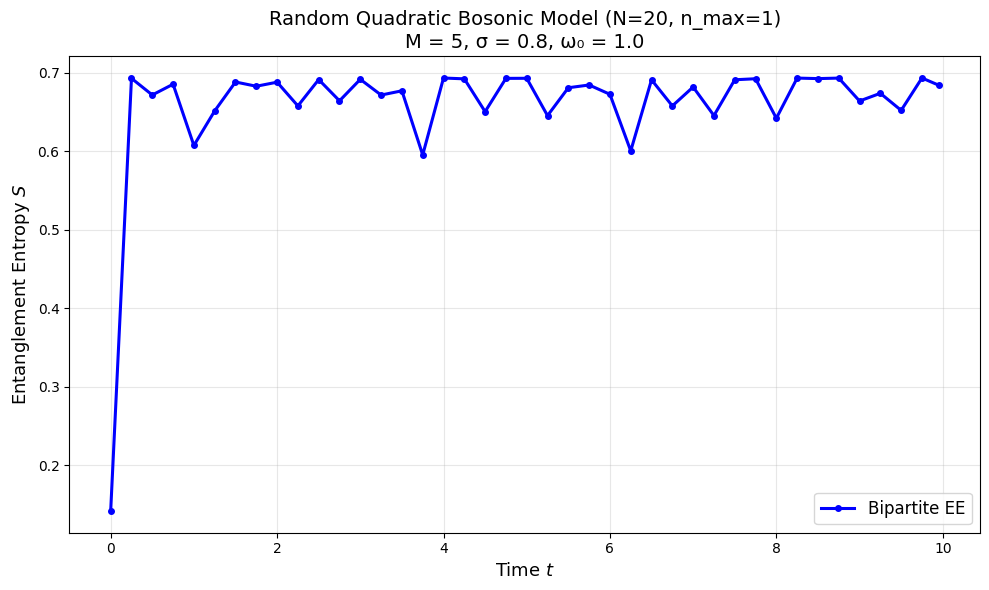

In [6]:
"""
Random Quadratic Bosonic Model (N=20, n_max=1)
Hamiltonian: H = ω₀ ∑ n̂_i + ∑_m |∑_i l_{m,i} b̂_i |²    with ω₀ = 1
Only plots Bipartite Entanglement Entropy vs Time
"""

import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from qiskit import QuantumCircuit, transpile
from qiskit.converters import circuit_to_gate
from qiskit_aer import AerSimulator
import bosonic_qiskit

# =============================================================================
# PARAMETERS
# =============================================================================

Nsites     = 20
cutoff     = 2                     # hard-core bosons (n=0 or 1)

omega0     = 1.0
M          = 5                     # ← You can change this
sigma      = 0.8                   # ← You can change this

dt         = 0.05
n_steps    = 200                   # total time = n_steps * dt ≈ 10

chi        = 128                   # MPS bond dimension

# =============================================================================
# Generate Coupling Matrix K
# =============================================================================

def generate_coupling_matrix(N, M, sigma, omega0=1.0, seed=42):
    np.random.seed(seed)
    L = (np.random.randn(M, N) + 1j * np.random.randn(M, N)) * sigma / np.sqrt(2)
    interaction = L.conj().T @ L
    K = omega0 * np.eye(N) + interaction
    return K


# =============================================================================
# Build Trotter Step
# =============================================================================

def build_trotter_step(Nsites, cutoff, K, dt):
    n_qubits_per_mode = 1   # since cutoff=2
    qmr = bosonic_qiskit.QumodeRegister(Nsites, n_qubits_per_mode)
    circuit = bosonic_qiskit.CVCircuit(qmr)

    # Off-diagonal: Beamsplitters
    for i in range(Nsites):
        for j in range(i+1, Nsites):
            kij = K[i,j]
            if abs(kij) > 1e-10:
                theta = -2 * np.abs(kij) * dt
                circuit.cv_bs(theta, qmr[i], qmr[j])

    # Diagonal terms (including ω0)
    for i in range(Nsites):
        phase = -K[i,i] * dt
        circuit.cv_snap(phase, 1, qmr[i])   # phase only on |1⟩

    return circuit_to_gate(circuit, label="U_K")


# =============================================================================
# MPS Simulator
# =============================================================================

sim = AerSimulator(
    method="matrix_product_state",
    matrix_product_state_max_bond_dimension=chi,
)


# =============================================================================
# Run Simulation
# =============================================================================

K = generate_coupling_matrix(Nsites, M, sigma, omega0)

trotter_gate = build_trotter_step(Nsites, cutoff, K, dt)

# Pre-transpile
hop_circ = QuantumCircuit(Nsites)
hop_circ.append(trotter_gate, range(Nsites))
HOP = transpile(hop_circ, sim, optimization_level=1)

# Initial state: One boson in the center
qc = QuantumCircuit(Nsites, Nsites)
qc.x(Nsites//2)

entropy_list = []
t_list = []

print("Running simulation...")

for step in range(n_steps):
    qc.compose(HOP, inplace=True)

    # Compute EE every 5 steps (for speed)
    if step % 5 == 0 or step == n_steps-1:
        qc_save = qc.copy()
        qc_save.save_matrix_product_state(label="mps")
        
        tqc = transpile(qc_save, sim, optimization_level=0)
        result = sim.run(tqc, shots=1).result()
        mps_data = result.data(0)["mps"]
        
        S = bond_entropy(mps_data, Nsites//2 - 1)
        
        entropy_list.append(S)
        t_list.append(step * dt)
        
    if step % 20 == 0:
        print(f"  Step {step:3d}/{n_steps}   t = {step*dt:.2f}   S = {S:.4f}")

print("Simulation finished.")


# =============================================================================
# Plot: Time vs Entanglement Entropy
# =============================================================================

plt.figure(figsize=(10, 6))
plt.plot(t_list, entropy_list, 'b-o', linewidth=2.2, markersize=4, label='Bipartite EE')

plt.xlabel('Time $t$', fontsize=13)
plt.ylabel('Entanglement Entropy $S$', fontsize=13)
plt.title(f'Random Quadratic Bosonic Model (N={Nsites}, n_max=1)\n'
          f'M = {M}, σ = {sigma}, ω₀ = {omega0}', fontsize=14)

plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

1D Disordered Bose-Hubbard - Half-Chain EE Evolution
N = 15 sites | χ = 64 | 10 disorders

Running Δ = 12.0 | 10 realizations
  Realization  1/10 | Final S = 0.312
  Realization  2/10 | Final S = 0.691
  Realization  3/10 | Final S = 0.187
  Realization  4/10 | Final S = 0.233
  Realization  5/10 | Final S = 0.060
  Realization  6/10 | Final S = 0.495
  Realization  7/10 | Final S = 0.134
  Realization  8/10 | Final S = 0.098
  Realization  9/10 | Final S = 0.564
  Realization 10/10 | Final S = 0.229
Running Δ = 20.0 | 10 realizations
  Realization  1/10 | Final S = 0.181
  Realization  2/10 | Final S = 0.253
  Realization  3/10 | Final S = 0.587
  Realization  4/10 | Final S = 0.033
  Realization  5/10 | Final S = 0.046
  Realization  6/10 | Final S = 0.516
  Realization  7/10 | Final S = 0.013
  Realization  8/10 | Final S = 0.235
  Realization  9/10 | Final S = 0.135
  Realization 10/10 | Final S = 0.011
Running Δ = 40.0 | 10 realizations
  Realization  1/10 | Final S = 0.192
  Real

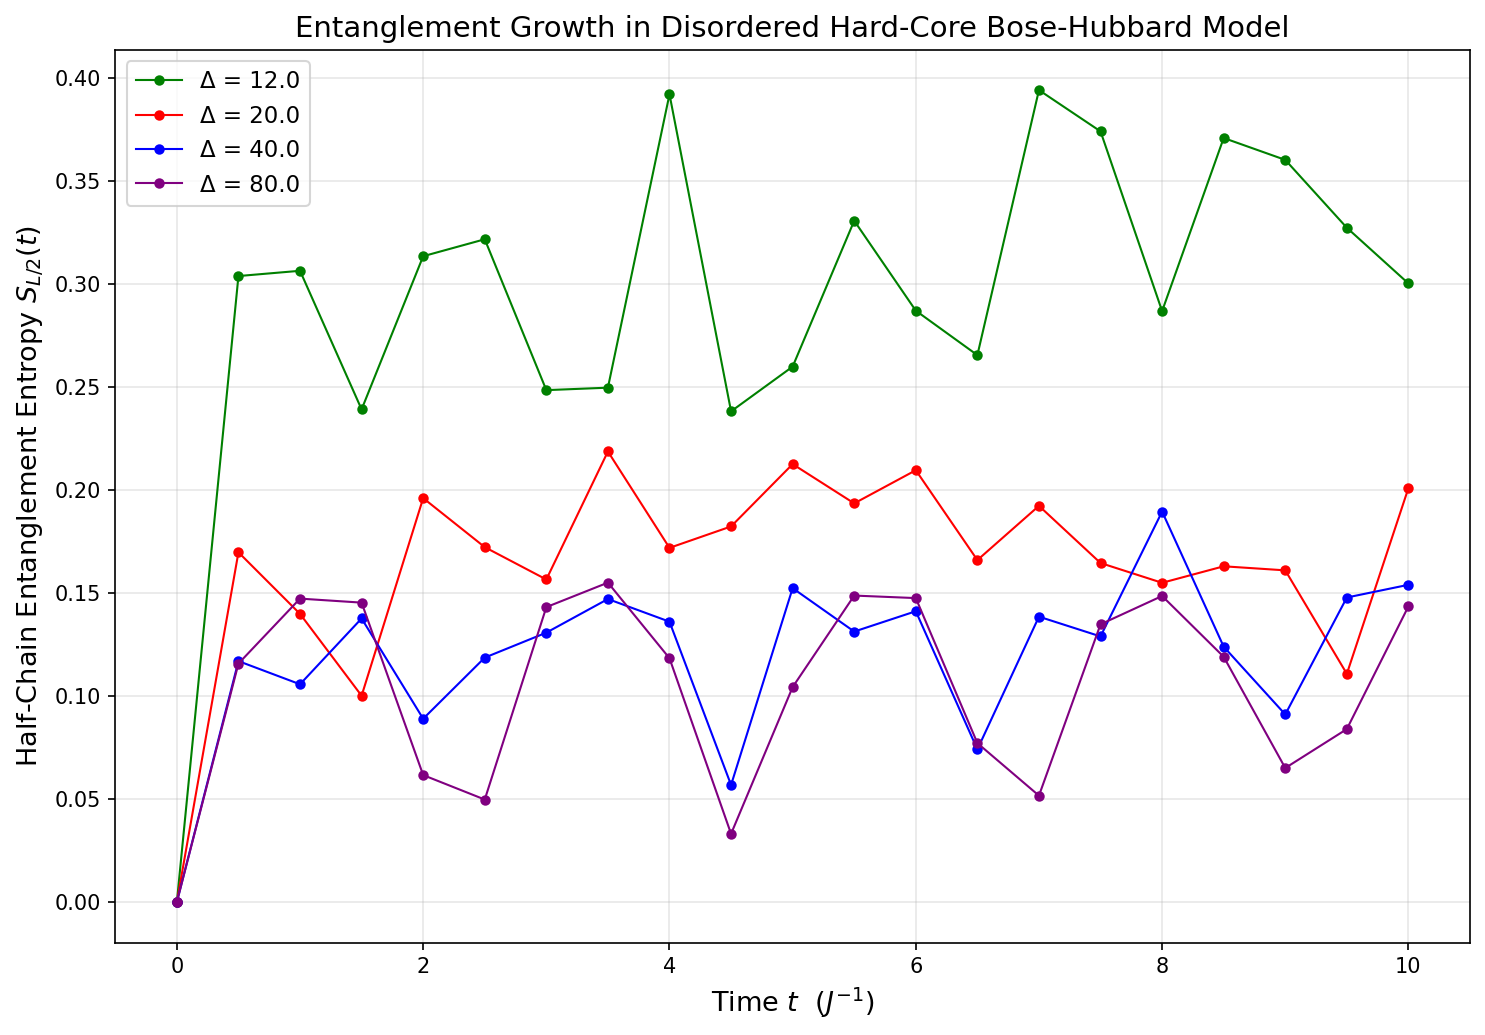

In [5]:


import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from qiskit import QuantumCircuit, transpile
from qiskit.converters import circuit_to_gate
from qiskit_aer import AerSimulator
import bosonic_qiskit

# =============================================================================
# PARAMETERS
# =============================================================================
Nsites      = 15
J           = 1.0
dt          = 0.05
n_steps     = 200                    # Total time t = n_steps * dt = 10 J^-1

chi         = 64                  # MPS bond dimension
n_disorder  = 10                     # Number of disorder realizations
save_every  = 10                      # Save state every N steps (for speed)

DELTA_LIST  = [12.0, 20.0, 40.0, 80.0]
COLORS      = ["green", "red", "blue", "purple"]

# =============================================================================
# SETUP
# =============================================================================
n_qubits_per_mode = 1
qmr = bosonic_qiskit.QumodeRegister(num_qumodes=Nsites, 
                                    num_qubits_per_qumode=n_qubits_per_mode)

def build_trotter_gate():
    """Build Trotter step for hopping"""
    circuit = bosonic_qiskit.CVCircuit(qmr)
    theta = J * dt
    
    # Even bonds
    for i in range(0, Nsites - 1, 2):
        circuit.cv_bs(theta, qmr[i], qmr[i + 1])
    # Odd bonds
    for i in range(1, Nsites - 1, 2):
        circuit.cv_bs(theta, qmr[i], qmr[i + 1])
    
    return circuit_to_gate(circuit, label="U_hop")


trotter_gate = build_trotter_gate()

# Simulator
sim = AerSimulator(
    method="matrix_product_state",
    matrix_product_state_max_bond_dimension=chi
)

# Pre-transpile hopping gate
hop_circ = QuantumCircuit(Nsites)
hop_circ.append(trotter_gate, range(Nsites))
HOP = transpile(hop_circ, sim, optimization_level=0)

# =============================================================================
# HALF-CHAIN ENTANGLEMENT ENTROPY
# =============================================================================
def half_chain_entropy(mps_data):
    
    _, lambdas = mps_data
    lam = np.array(lambdas[Nsites//2 - 1], dtype=float)   # Central bond
    lam = lam[lam > 1e-12]
    p = lam**2
    p /= p.sum()
    S = -np.sum(p * np.log(p + 1e-15))
    return float(S)

# =============================================================================
# TIME EVOLUTION + MEASUREMENT
# =============================================================================
def run_delta(delta):
    sigma = delta / (2 * np.sqrt(2 * np.log(2)))
    rng = np.random.default_rng()
    
    times = np.arange(0, n_steps + 1, save_every) * dt
    S_avg = np.zeros(len(times))
    
    print(f"Running Δ = {delta} | {n_disorder} realizations")
    
    for r in range(n_disorder):
        disorder = rng.normal(0, sigma, Nsites)
        
        qc = QuantumCircuit(Nsites)
        
        # Initial Néel state
        for i in range(0, Nsites, 2):
            qc.x(i)
        
        S_real = []
        for step in range(n_steps + 1):
            if step > 0:
                # Disorder potential
                for i in range(Nsites):
                    qc.rz(-disorder[i] * dt, i)
                # Hopping
                qc.compose(HOP, inplace=True)
            
            # Save state at intervals
            if step % save_every == 0:
                temp = qc.copy()
                temp.save_matrix_product_state(label="mps")
                
                tqc = transpile(temp, sim, optimization_level=1)
                result = sim.run(tqc, shots=1).result()
                
                mps = result.data(0)["mps"]
                S_real.append(half_chain_entropy(mps))
        
        S_avg += np.array(S_real)
        print(f"  Realization {r+1:2d}/{n_disorder} | Final S = {S_real[-1]:.3f}")
    
    S_avg /= n_disorder
    return times, S_avg


# =============================================================================
# MAIN EXECUTION
# =============================================================================
print(f"1D Disordered Bose-Hubbard - Half-Chain EE Evolution")
print(f"N = {Nsites} sites | χ = {chi} | {n_disorder} disorders\n")

results = {}
for delta in DELTA_LIST:
    results[delta] = run_delta(delta)

# =============================================================================
# PLOTTING
# =============================================================================
plt.figure(figsize=(10, 7), dpi=150)

for i, delta in enumerate(DELTA_LIST):
    t, S = results[delta]
    plt.plot(t, S, color=COLORS[i], linewidth=1,  marker='o', 
             markersize=4, label=f"Δ = {delta}")


plt.xlabel(r"Time $t$  ($J^{-1}$)", fontsize=13)
plt.ylabel(r"Half-Chain Entanglement Entropy $S_{L/2}(t)$", fontsize=13)
plt.title("Entanglement Growth in Disordered Hard-Core Bose-Hubbard Model", 
          fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("EE_vs_Time_HalfChain.png", dpi=200, bbox_inches='tight')
plt.show()

1D Disordered Bose-Hubbard - Half-Chain EE Evolution
N = 10 sites | χ = 128 | 30 disorders

Running Δ = 12.0 | 30 realizations
  Realization  1/30 | Final S = 0.117
  Realization  2/30 | Final S = 0.309
  Realization  3/30 | Final S = 0.057
  Realization  4/30 | Final S = 0.892
  Realization  5/30 | Final S = 0.407
  Realization  6/30 | Final S = 0.018
  Realization  7/30 | Final S = 0.638
  Realization  8/30 | Final S = 0.154
  Realization  9/30 | Final S = 0.670
  Realization 10/30 | Final S = 0.152
  Realization 11/30 | Final S = 0.059
  Realization 12/30 | Final S = 0.134
  Realization 13/30 | Final S = 0.367
  Realization 14/30 | Final S = 0.206
  Realization 15/30 | Final S = 0.518
  Realization 16/30 | Final S = 0.204
  Realization 17/30 | Final S = 0.159
  Realization 18/30 | Final S = 0.048
  Realization 19/30 | Final S = 0.283
  Realization 20/30 | Final S = 0.308
  Realization 21/30 | Final S = 0.112
  Realization 22/30 | Final S = 0.105
  Realization 23/30 | Final S = 0.463

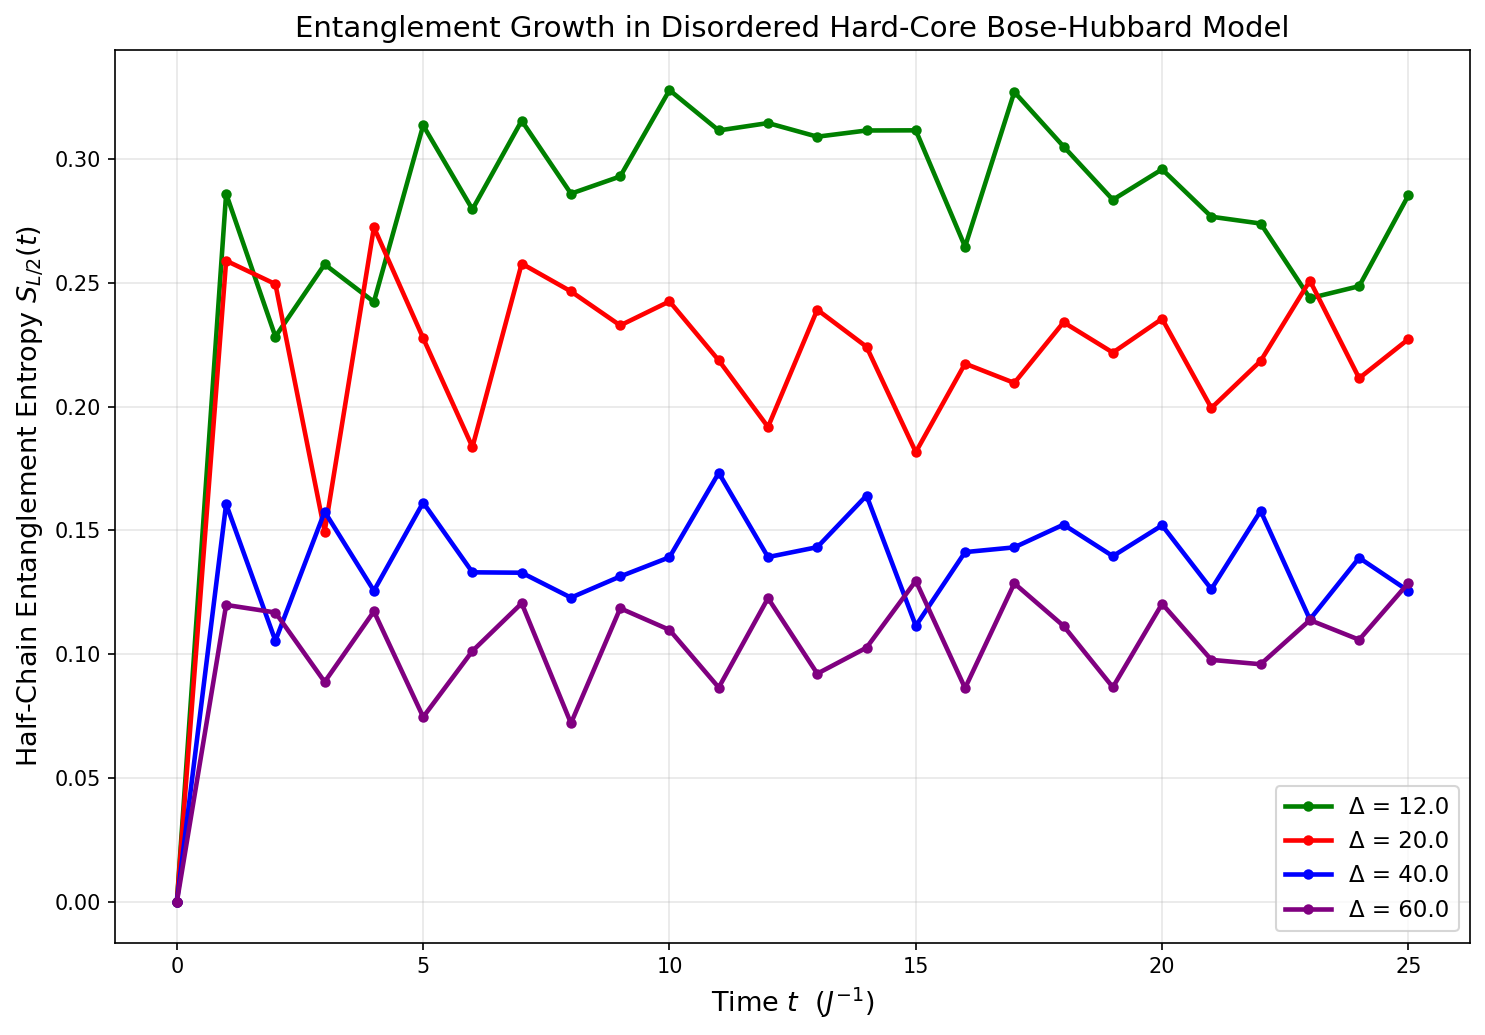

In [3]:


import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from qiskit import QuantumCircuit, transpile
from qiskit.converters import circuit_to_gate
from qiskit_aer import AerSimulator
import bosonic_qiskit

# =============================================================================
# PARAMETERS
# =============================================================================
Nsites      = 10                    # Keep small
J           = 1.0
dt          = 0.05
n_steps     = 500                   # ← Increased: t = 25 J^{-1}

chi         = 128               # Moderate bond dimension
n_disorder  = 30                 # Reduced for speed (most important!)
save_every  = 20                      # Save state every N steps (for speed)

DELTA_LIST  = [12.0, 20.0, 40.0, 60.0]
COLORS      = ["green", "red", "blue", "purple"]

# =============================================================================
# SETUP
# =============================================================================
n_qubits_per_mode = 1
qmr = bosonic_qiskit.QumodeRegister(num_qumodes=Nsites, 
                                    num_qubits_per_qumode=n_qubits_per_mode)

def build_trotter_gate():
    """Build Trotter step for hopping"""
    circuit = bosonic_qiskit.CVCircuit(qmr)
    theta = J * dt
    
    # Even bonds
    for i in range(0, Nsites - 1, 2):
        circuit.cv_bs(theta, qmr[i], qmr[i + 1])
    # Odd bonds
    for i in range(1, Nsites - 1, 2):
        circuit.cv_bs(theta, qmr[i], qmr[i + 1])
    
    return circuit_to_gate(circuit, label="U_hop")


trotter_gate = build_trotter_gate()

# Simulator
sim = AerSimulator(
    method="matrix_product_state",
    matrix_product_state_max_bond_dimension=chi
)

# Pre-transpile hopping gate
hop_circ = QuantumCircuit(Nsites)
hop_circ.append(trotter_gate, range(Nsites))
HOP = transpile(hop_circ, sim, optimization_level=0)

# =============================================================================
# HALF-CHAIN ENTANGLEMENT ENTROPY
# =============================================================================
def half_chain_entropy(mps_data):
    """Compute entanglement entropy across the central cut (bond 9 for N=20)"""
    _, lambdas = mps_data
    lam = np.array(lambdas[Nsites//2 - 1], dtype=float)   # Central bond
    lam = lam[lam > 1e-12]
    p = lam**2
    p /= p.sum()
    S = -np.sum(p * np.log(p + 1e-15))
    return float(S)

# =============================================================================
# TIME EVOLUTION + MEASUREMENT
# =============================================================================
def run_delta(delta):
    sigma = delta / (2 * np.sqrt(2 * np.log(2)))
    rng = np.random.default_rng()
    
    times = np.arange(0, n_steps + 1, save_every) * dt
    S_avg = np.zeros(len(times))
    
    print(f"Running Δ = {delta} | {n_disorder} realizations")
    
    for r in range(n_disorder):
        disorder = rng.normal(0, sigma, Nsites)
        
        qc = QuantumCircuit(Nsites)
        
        # Initial Néel state
        for i in range(0, Nsites, 2):
            qc.x(i)
        
        S_real = []
        for step in range(n_steps + 1):
            if step > 0:
                # Disorder potential
                for i in range(Nsites):
                    qc.rz(-disorder[i] * dt, i)
                # Hopping
                qc.compose(HOP, inplace=True)
            
            # Save state at intervals
            if step % save_every == 0:
                temp = qc.copy()
                temp.save_matrix_product_state(label="mps")
                
                tqc = transpile(temp, sim, optimization_level=1)
                result = sim.run(tqc, shots=1).result()
                
                mps = result.data(0)["mps"]
                S_real.append(half_chain_entropy(mps))
        
        S_avg += np.array(S_real)
        print(f"  Realization {r+1:2d}/{n_disorder} | Final S = {S_real[-1]:.3f}")
    
    S_avg /= n_disorder
    return times, S_avg


# =============================================================================
# MAIN EXECUTION
# =============================================================================
print(f"1D Disordered Bose-Hubbard - Half-Chain EE Evolution")
print(f"N = {Nsites} sites | χ = {chi} | {n_disorder} disorders\n")

results = {}
for delta in DELTA_LIST:
    results[delta] = run_delta(delta)

# =============================================================================
# PLOTTING
# =============================================================================
plt.figure(figsize=(10, 7), dpi=150)

for i, delta in enumerate(DELTA_LIST):
    t, S = results[delta]
    plt.plot(t, S, color=COLORS[i], linewidth=2.2, marker='o', 
             markersize=4, label=f"Δ = {delta}")



plt.xlabel(r"Time $t$  ($J^{-1}$)", fontsize=13)
plt.ylabel(r"Half-Chain Entanglement Entropy $S_{L/2}(t)$", fontsize=13)
plt.title("Entanglement Growth in Disordered Hard-Core Bose-Hubbard Model", 
          fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("EE_vs_Time_HalfChain.png", dpi=200, bbox_inches='tight')
plt.show()

Running Quadratic Bosonic Model | N=12, M=5, σ=0.8, ω0=1.0
  Step   0 | t =  0.00 | S = -0.0000
  Step  20 | t =  1.00 | S = 0.6928
  Step  40 | t =  2.00 | S = 0.4815
  Step  60 | t =  3.00 | S = 0.6011
  Step  80 | t =  4.00 | S = 0.6553
  Step 100 | t =  5.00 | S = 0.6077
  Step 120 | t =  6.00 | S = 0.6554
  Step 140 | t =  7.00 | S = 0.6508
  Step 160 | t =  8.00 | S = 0.6903
  Step 180 | t =  9.00 | S = 0.6111
  Step 200 | t = 10.00 | S = 0.6809


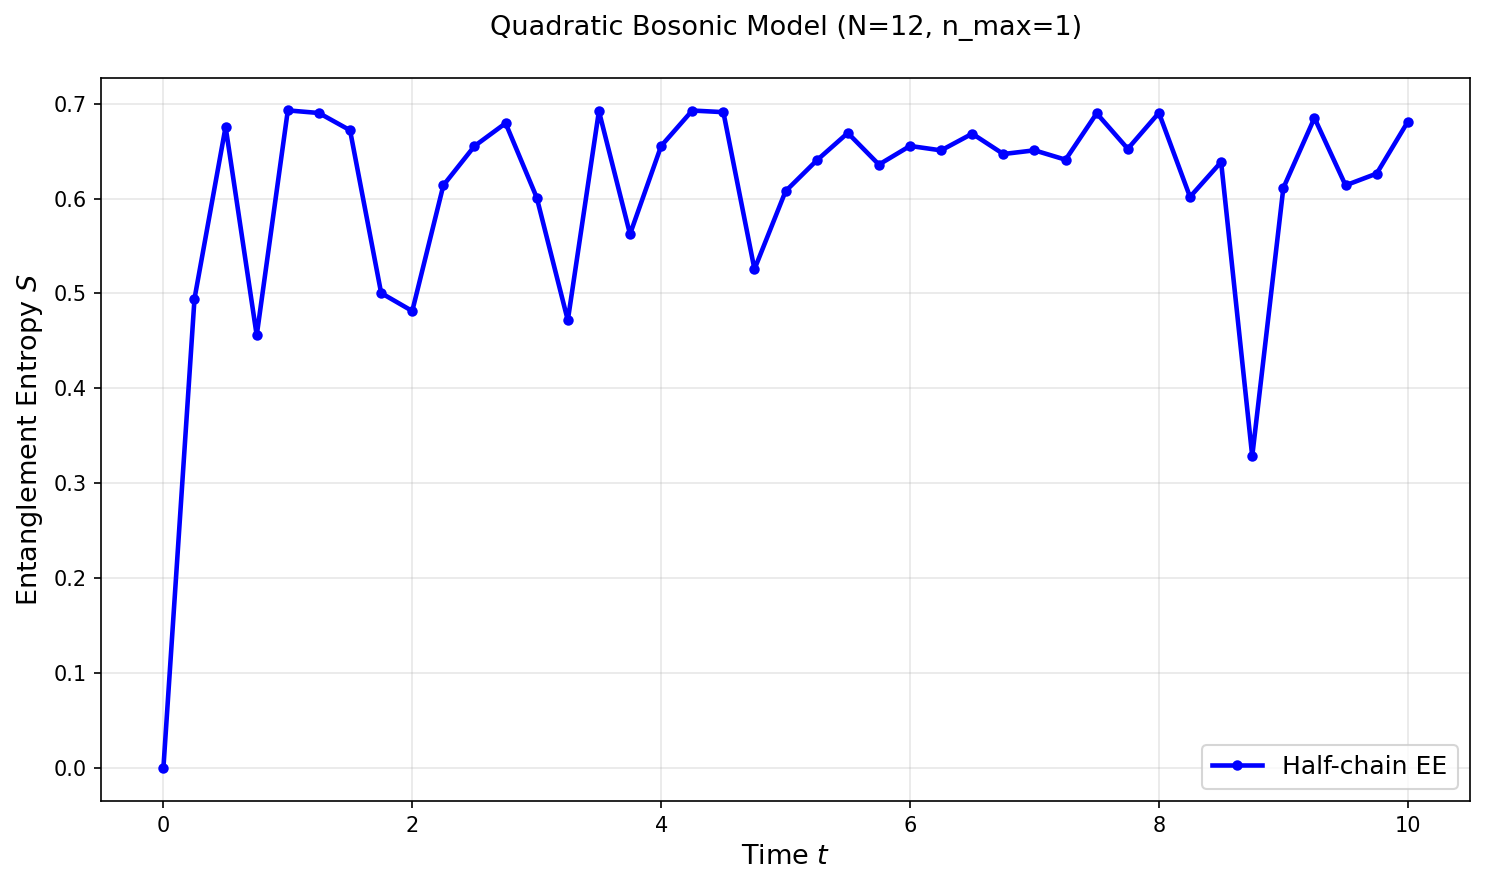

Simulation finished.


In [11]:
"""
Random Quadratic Bosonic Model - Improved Implementation
Hamiltonian: H = ω₀ ∑ n_i + ∑_m |∑_i l_{m,i} b_i|^2
"""

import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from qiskit import QuantumCircuit, transpile
from qiskit.converters import circuit_to_gate
from qiskit_aer import AerSimulator
import bosonic_qiskit

# =============================================================================
# PARAMETERS
# =============================================================================
Nsites     = 12                    # Small for fast testing
omega0     = 1.0
M          = 5
sigma      = 0.8

dt         = 0.05
n_steps    = 200                   # total time t = 10
chi        = 64                    # smaller chi for speed

# =============================================================================
# Generate Hermitian Coupling Matrix K
# =============================================================================
def generate_coupling_matrix(N, M, sigma, omega0=1.0, seed=42):
    np.random.seed(seed)
    L = (np.random.randn(M, N) + 1j * np.random.randn(M, N)) * sigma / np.sqrt(2)
    K = omega0 * np.eye(N) + L.conj().T @ L
    return K

K = generate_coupling_matrix(Nsites, M, sigma, omega0)

# =============================================================================
# Bond Entropy Function
# =============================================================================
def bond_entropy(mps_data, bond_idx):
    """Compute von Neumann entropy from Schmidt values at a given bond"""
    _, lambdas = mps_data
    lam = np.array(lambdas[bond_idx], dtype=float)
    lam = lam[lam > 1e-12]
    p = lam**2
    p /= p.sum()
    S = -np.sum(p * np.log(p + 1e-15))
    return float(S)

# =============================================================================
# Build Trotter Step (Improved)
# =============================================================================
def build_trotter_step(Nsites, K, dt):
    qmr = bosonic_qiskit.QumodeRegister(Nsites, 1)
    circuit = bosonic_qiskit.CVCircuit(qmr)

    # Off-diagonal terms
    for i in range(Nsites):
        for j in range(i+1, Nsites):
            kij = K[i, j]
            if abs(kij) > 1e-12:
                r = np.abs(kij)
                phi = np.angle(kij)
                
                theta = -2 * r * dt
                circuit.cv_bs(theta, qmr[i], qmr[j])
                
                # Phase correction
                circuit.cv_snap(-phi * dt, 1, qmr[i])
                circuit.cv_snap( phi * dt, 1, qmr[j])

    # Diagonal terms
    for i in range(Nsites):
        phase = -K[i, i].real * dt
        circuit.cv_snap(phase, 1, qmr[i])

    return circuit_to_gate(circuit, label="U_trotter")


trotter_gate = build_trotter_step(Nsites, K, dt)

# =============================================================================
# Simulator Setup
# =============================================================================
sim = AerSimulator(
    method="matrix_product_state",
    matrix_product_state_max_bond_dimension=chi
)

# Pre-transpile the gate
hop_circ = QuantumCircuit(Nsites)
hop_circ.append(trotter_gate, range(Nsites))
HOP = transpile(hop_circ, sim, optimization_level=1)

# =============================================================================
# Time Evolution + Measurement
# =============================================================================
qc = QuantumCircuit(Nsites)
qc.x(Nsites//2)                    # Initial state: one boson in the center

entropy_list = []
t_list = []

print(f"Running Quadratic Bosonic Model | N={Nsites}, M={M}, σ={sigma}, ω0={omega0}")

for step in range(n_steps + 1):
    if step > 0:
        qc.compose(HOP, inplace=True)
    
    # Save entropy every 5 steps
    if step % 5 == 0 or step == n_steps:
        qc_save = qc.copy()
        qc_save.save_matrix_product_state(label="mps")
        
        tqc = transpile(qc_save, sim, optimization_level=0)
        result = sim.run(tqc, shots=1).result()
        
        mps_data = result.data(0)["mps"]
        S = bond_entropy(mps_data, Nsites//2 - 1)   # central bond
        
        entropy_list.append(S)
        t_list.append(step * dt)
        
    if step % 20 == 0:
        print(f"  Step {step:3d} | t = {step*dt:5.2f} | S = {S:.4f}")

# =============================================================================
# Plot
# =============================================================================
plt.figure(figsize=(10, 6), dpi=150)
plt.plot(t_list, entropy_list, 'b-o', linewidth=2.2, markersize=4, label='Half-chain EE')

plt.xlabel('Time $t$', fontsize=13)
plt.ylabel('Entanglement Entropy $S$', fontsize=13)
plt.title(f'Quadratic Bosonic Model (N={Nsites}, n_max=1)\n'
          ,fontsize=13)

plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig("Quadratic_Boson_EE.png", dpi=200, bbox_inches='tight')
plt.show()

print("Simulation finished.")

Δ = 12.0 | Long time simulation (t_max=100.0)
   Realization  1/12 | Final S = 0.647
   Realization  2/12 | Final S = 0.811
   Realization  3/12 | Final S = 0.244
   Realization  4/12 | Final S = 0.604
   Realization  5/12 | Final S = 0.049
   Realization  6/12 | Final S = 0.035
   Realization  7/12 | Final S = 0.634
   Realization  8/12 | Final S = 0.573
   Realization  9/12 | Final S = 0.279
   Realization 10/12 | Final S = 0.566
   Realization 11/12 | Final S = 0.589
   Realization 12/12 | Final S = 0.786
Δ = 20.0 | Long time simulation (t_max=100.0)
   Realization  1/12 | Final S = 0.032
   Realization  2/12 | Final S = 0.131
   Realization  3/12 | Final S = 0.022
   Realization  4/12 | Final S = 0.682
   Realization  5/12 | Final S = 0.701
   Realization  6/12 | Final S = 0.001
   Realization  7/12 | Final S = 0.005
   Realization  8/12 | Final S = 0.115
   Realization  9/12 | Final S = 0.105
   Realization 10/12 | Final S = 0.151
   Realization 11/12 | Final S = 0.681
   Realizat

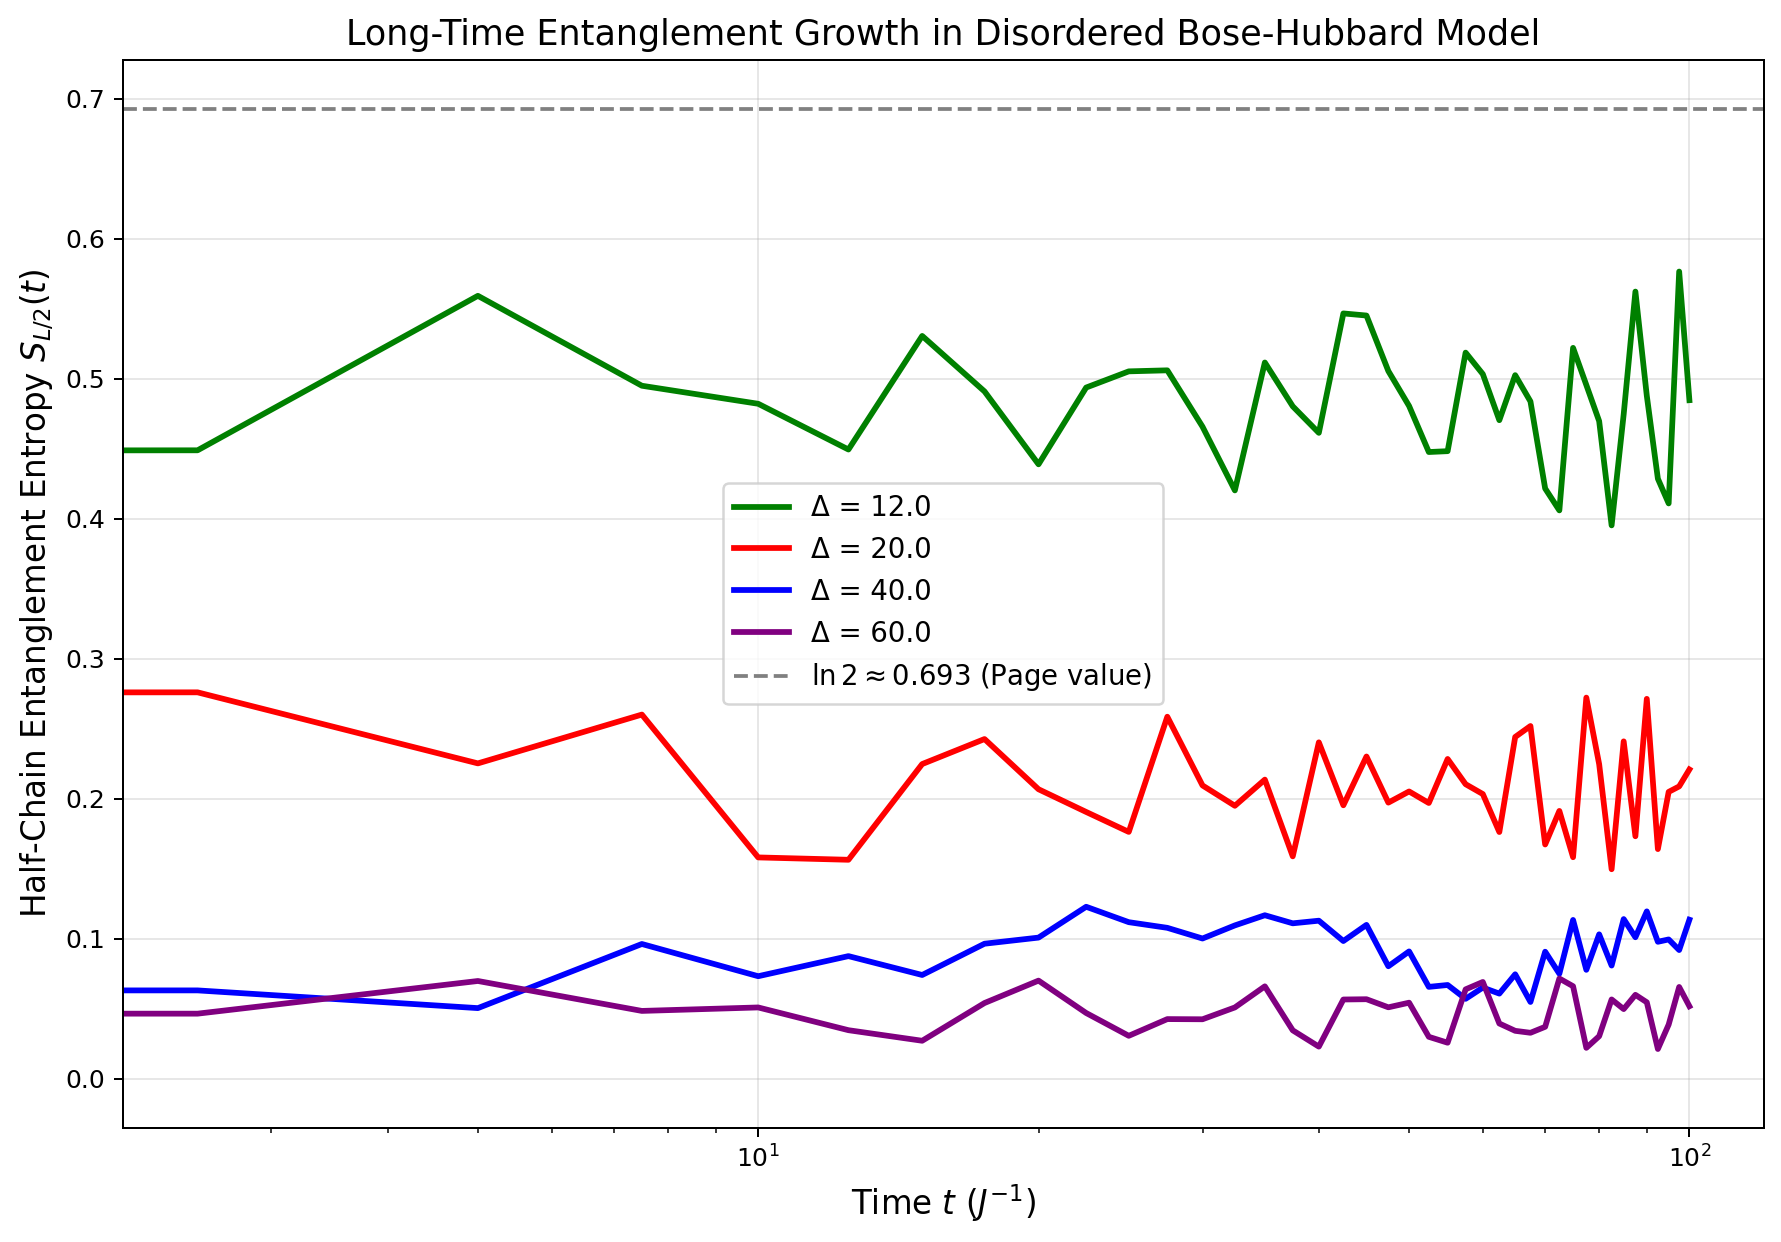

In [1]:
"""
Long-Time Simulation - Optimized for Speed
"""

import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from qiskit import QuantumCircuit, transpile
from qiskit.converters import circuit_to_gate
from qiskit_aer import AerSimulator
import bosonic_qiskit

# =============================================================================
# PARAMETERS - Optimized for Long Time
# =============================================================================
Nsites      = 12
J           = 1.0
dt          = 0.05
n_steps     = 2000                 

chi         = 96                    
n_disorder  = 12                    
save_every  = 50                    

DELTA_LIST  = [12.0, 20.0, 40.0, 60.0]
COLORS      = ["green", "red", "blue", "purple"]

# =============================================================================
# SETUP
# =============================================================================
qmr = bosonic_qiskit.QumodeRegister(num_qumodes=Nsites, num_qubits_per_qumode=1)

def build_trotter_gate():
    circuit = bosonic_qiskit.CVCircuit(qmr)
    theta = J * dt
    for i in range(0, Nsites-1, 2):
        circuit.cv_bs(theta, qmr[i], qmr[i+1])
    for i in range(1, Nsites-1, 2):
        circuit.cv_bs(theta, qmr[i], qmr[i+1])
    return circuit_to_gate(circuit, label="U_hop")

trotter_gate = build_trotter_gate()

sim = AerSimulator(method="matrix_product_state", 
                   matrix_product_state_max_bond_dimension=chi)

hop_circ = QuantumCircuit(Nsites)
hop_circ.append(trotter_gate, range(Nsites))
HOP = transpile(hop_circ, sim, optimization_level=2)   # Higher optimization

# =============================================================================
# ENTROPY
# =============================================================================
def half_chain_entropy(mps_data):
    _, lambdas = mps_data
    central_bond = Nsites // 2 - 1
    lam = np.array(lambdas[central_bond], dtype=float)
    lam = lam[lam > 1e-12]
    p = lam**2
    p /= p.sum() + 1e-15
    return -np.sum(p * np.log(p + 1e-15))

# =============================================================================
# LONG-TIME RUN FUNCTION
# =============================================================================
def run_delta_long(delta):
    sigma = delta / (2 * np.sqrt(2 * np.log(2)))
    rng = np.random.default_rng()
    
    times = np.arange(0, n_steps + 1, save_every) * dt
    S_avg = np.zeros(len(times))
    
    print(f"Δ = {delta} | Long time simulation (t_max={n_steps*dt})")
    
    for r in range(n_disorder):
        disorder = rng.normal(0, sigma, Nsites)
        qc = QuantumCircuit(Nsites)
        
        # Initial Néel state
        for i in range(0, Nsites, 2):
            qc.x(i)
        
        S_real = []
        for step in range(n_steps + 1):
            if step > 0:
                for i in range(Nsites):
                    qc.rz(-disorder[i] * dt, i)
                qc.compose(HOP, inplace=True)
            
            if step % save_every == 0:
                temp = qc.copy()
                temp.save_matrix_product_state("mps")
                tqc = transpile(temp, sim, optimization_level=1)
                result = sim.run(tqc, shots=1).result()
                mps = result.data(0)["mps"]
                S_real.append(half_chain_entropy(mps))
        
        S_avg += np.array(S_real)
        print(f"   Realization {r+1:2d}/{n_disorder} | Final S = {S_real[-1]:.3f}")
    
    return times, S_avg / n_disorder


# =============================================================================
# MAIN
# =============================================================================
results = {}
for delta in DELTA_LIST:
    results[delta] = run_delta_long(delta)

# =============================================================================
# PLOT (with Log Scale - Recommended for long times)
# =============================================================================
plt.figure(figsize=(10, 7), dpi=180)

for i, delta in enumerate(DELTA_LIST):
    t, S = results[delta]
    plt.plot(t, S, color=COLORS[i], linewidth=2.3, label=f"Δ = {delta}")

plt.axhline(np.log(2), color='gray', linestyle='--', label=r'$\ln 2 \approx 0.693$ (Page value)')

plt.xlabel(r"Time $t$ ($J^{-1}$)", fontsize=13)
plt.ylabel(r"Half-Chain Entanglement Entropy $S_{L/2}(t)$", fontsize=13)
plt.title("Long-Time Entanglement Growth in Disordered Bose-Hubbard Model", fontsize=14)

plt.xscale('log')                    # ← Very useful for long times
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("EE_vs_Time_Long_Log.png", dpi=250, bbox_inches='tight')
plt.show()